Text(0.5, 1.0, 'waiting time dist - Poisson generated')

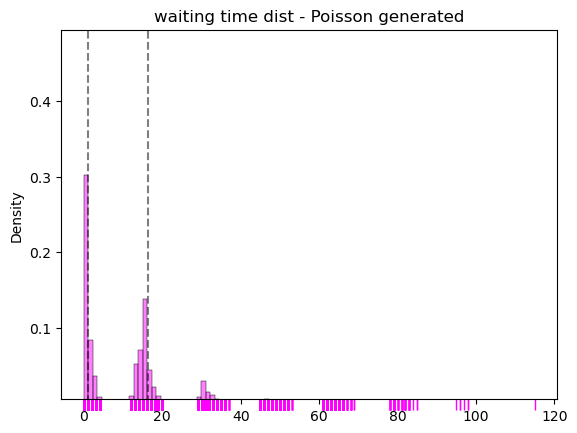

In [184]:
from generate_repeater import generate_repeater_from_dist, observing_window_mask
from plotting import plot_waiting_time_distribution
import numpy as np
import seaborn as sns

toas_poisson = generate_repeater_from_dist(16.3, 4.5, 10000000, dist = 'poisson', rate = 50)
masked_toas_poisson = toas_poisson[observing_window_mask(toas_poisson)]
gaps_poisson = np.diff(masked_toas_poisson)
bins, color, period = 100, "magenta", [1, 16.3]
ax1 = sns.histplot(gaps_poisson, bins = bins, stat = "density", alpha = 0.5, color = color)
if period:
    ax1.vlines(x = period, ymin = 0, ymax = 0.5, color = "black", linestyles="--", alpha = 0.5)
ax1 = sns.rugplot(gaps_poisson, color = "magenta", height = -0.03, clip_on = False)
ax1.set_title("waiting time dist - Poisson generated")

Text(0.5, 1.0, 'waiting time dist - Weibull generated')

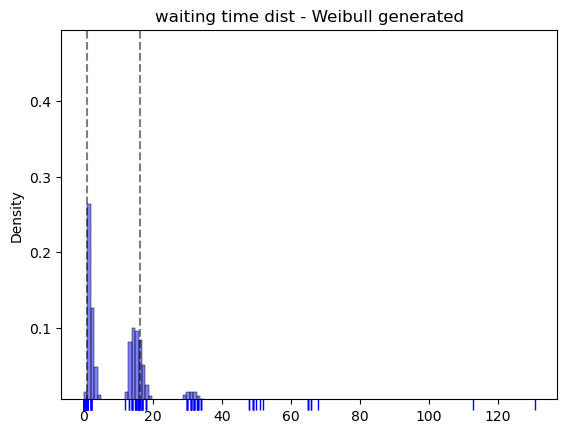

In [185]:
toas_weibull = generate_repeater_from_dist(16.3, 4.5, 10000000, dist = 'weibull', shape = 2.5, mean_wait = 1 / 50)
masked_toas_weibull = toas_weibull[observing_window_mask(toas_weibull)]
gaps_weibull = np.diff(masked_toas_weibull)
bins, color, period = 100, "blue", [1, 16.3]
ax1 = sns.histplot(gaps_weibull, bins = bins, stat = "density", alpha = 0.5, color = color)
if period:
    ax1.vlines(x = period, ymin = 0, ymax = 0.5, color = "black", linestyles="--", alpha = 0.5)
ax1 = sns.rugplot(gaps, color = "blue", height = -0.03, clip_on = False)
ax1.set_title("waiting time dist - Weibull generated")


Text(0.5, 1.0, 'waiting time dist - real R3 data')

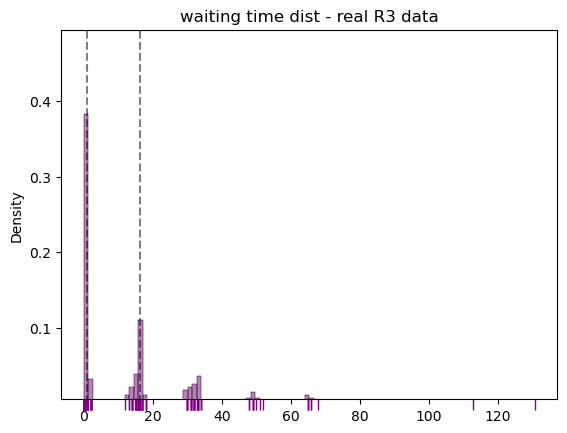

In [186]:
# Same for real data
import json as js

toas_r3 = []
with open("D:\Thesis\data\known_clusters.json", "r") as f:
    data = js.load(f)
for event in data["sources"]["FRB20180916B"]["events"]:
    toas_r3.append(event["timestamp_utc"])
toas_r3 = np.array(toas_r3).astype(np.datetime64)
toas_r3 = (toas_r3 - toas_r3[0]).astype('timedelta64[s]').astype(float) / 86400 #turn into days from 1st detection
gaps_r3 = np.diff(toas_r3)
bins, color, period = 100, "purple", [1, 16.3]
ax1 = sns.histplot(gaps_r3, bins = bins, stat = "density", alpha = 0.5, color = color)
if period:
    ax1.vlines(x = period, ymin = 0, ymax = 0.5, color = "black", linestyles="--", alpha = 0.5)
ax1 = sns.rugplot(gaps_r3, color = "purple", height = -0.03, clip_on = False)
ax1.set_title("waiting time dist - real R3 data")

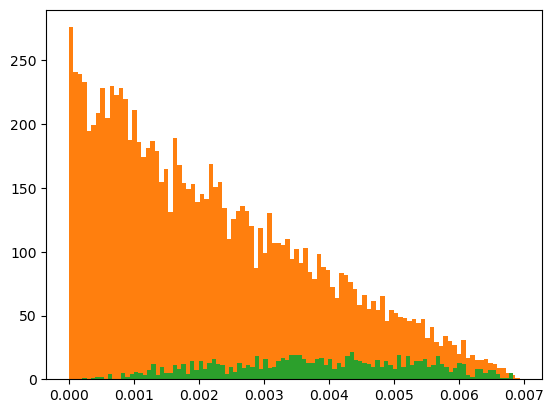

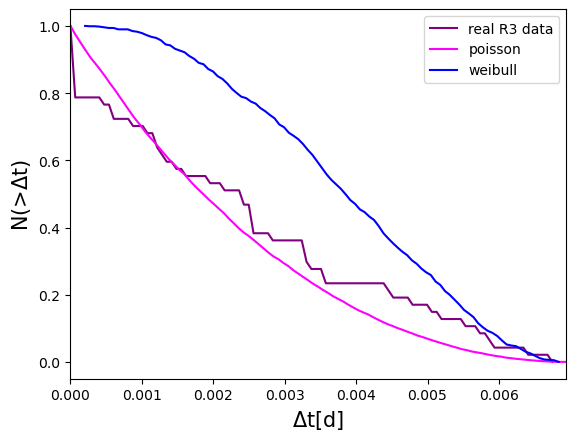

In [189]:
# look at the cdf

import matplotlib.pyplot as plt

gaps_r3_small = gaps_r3[gaps_r3 < 1/144]
counts_real, bins_real, bars_real = plt.hist(gaps_r3_small, bins = 100)
ddf_real = [1]
tot_counts_real = np.sum(counts_real)
sofar = tot_counts_real
for i in range(len(counts_real)):
    sofar = sofar - counts_real[i]
    ddf_real.append(sofar / tot_counts_real)

gaps_poisson_small = gaps_poisson[gaps_poisson < 1/144]
counts_poisson, bins_poisson, bars_poisson = plt.hist(gaps_poisson_small, bins = 100)
ddf_poisson = [1]
tot_counts_poisson = np.sum(counts_poisson)
sofar = tot_counts_poisson
for i in range(len(counts_poisson)):
    sofar = sofar - counts_poisson[i]
    ddf_poisson.append(sofar/tot_counts_poisson)

gaps_weibull_small = gaps_weibull[gaps_weibull < 1/144]
counts_weibull, bins_weibull, bars_weibull = plt.hist(gaps_weibull_small, bins = 100)
ddf_weibull = [1]
tot_counts_weibull = np.sum(counts_weibull)
sofar = tot_counts_weibull
for i in range(len(counts_weibull)):
    sofar = sofar - counts_weibull[i]
    ddf_weibull.append(sofar/tot_counts_weibull)
plt.show()

plt.plot(bins_real, ddf_real, color = "purple", label = "real R3 data")
plt.plot(bins_poisson, ddf_poisson, color = "magenta", label = "poisson")
plt.plot(bins_weibull, ddf_weibull, color = "blue", label = "weibull")
plt.xlim(0, 1/144)
plt.xlabel("$\Delta$t[d]", fontsize = 15)
plt.ylabel("N(>$\Delta$t)", fontsize = 15)
#plt.vlines(16.3, 0, 1, color = "black", linestyles = "--", label = "16.3 d")
plt.legend()
plt.show()

In [192]:
from generate_repeater import generate_repeater_from_dist

In [195]:
toas = generate_repeater_from_dist(period = 0, window = 999999, n_points = 100000, dist = "poisson", rate = 50)

ValueError: period and window must be > 0